In [1]:
import pandas as pd
import numpy as np
import pymc as pm
import matplotlib.pyplot as plt
import seaborn as sns
import pytensor.tensor as tt
import arviz as az
from pathlib import Path

# Project root (notebooks/ → one level up)
base_path = Path.cwd().parent

# Define paths
data_path = base_path / "data" / "processed" / "brent_oil_prices_cleaned.csv"
events_path = base_path / "data" / "raw" / "key_events.csv"
results_dir = base_path / "results"
plots_dir = results_dir / "plots"

# Ensure results directories exist
plots_dir.mkdir(parents=True, exist_ok=True)

# Plot style
plt.style.use('seaborn-v0_8')
%matplotlib inline


In [2]:
# Step 1: Load data
data_path = f'{base_path}/data/processed/brent_oil_prices_cleaned.csv'
events_path = f'{base_path}/data/raw/key_events.csv'
df = pd.read_csv(data_path, index_col='Date', parse_dates=True)
events = pd.read_csv(events_path, parse_dates=['Date'])

# Compute log returns if not present
if 'Log_Returns' not in df.columns:
    df['Log_Returns'] = np.log(df['Price']).diff()

In [29]:
# Step 2: Prepare data for modeling
# Subsample to semi-annual averages to reduce runtime
df_semiannual = df.resample('2QE').mean()  # Semi-annual end aggregation
df_semiannual = df_semiannual.dropna(subset=['Log_Returns'])
log_returns = df_semiannual['Log_Returns'].values
dates = df_semiannual.index  # Use index directly
n_points = len(log_returns)

# Verify shapes
print(f"Shape of dates: {dates.shape}, Shape of log_returns: {log_returns.shape}")
assert len(dates) == len(log_returns), "Mismatch between dates and log_returns lengths"
assert n_points > 10, "Insufficient data points after subsampling"

Shape of dates: (72,), Shape of log_returns: (72,)


In [30]:
# Step 3: Bayesian Change Point Model
# Prepare standardized series (helps sampler speed & stability)
y = log_returns.copy()
y_mean, y_std = np.mean(y), np.std(y)
y_stdzd = (y - y_mean) / y_std

n_change_points = 3
idx = np.arange(n_points)

with pm.Model() as model:
    # Continuous change point locations via sorted Beta
    alpha = pm.Beta('alpha', alpha=2, beta=2, shape=n_change_points)
    tau = pm.Deterministic('tau', tt.sort(alpha) * n_points)

    # Vectorized segment index
    seg = tt.sum((idx[:, None] >= tau[None, :]), axis=1)

    # Priors for each segment (on standardized scale)
    mu = pm.Normal('mu', mu=0.0, sigma=1.5, shape=n_change_points + 1)  # Widened sigma
    sigma = pm.HalfNormal('sigma', sigma=1.5, shape=n_change_points + 1)  # Widened sigma

    # Likelihood
    pm.Normal('obs', mu=mu[seg], sigma=sigma[seg], observed=y_stdzd)

    # Optimized sampling settings
    trace = pm.sample(
        draws=2000,
        tune=1000,
        chains=4,
        cores=4,
        target_accept=0.95,
        max_treedepth=15,
        init="jitter+adapt_diag",
        return_inferencedata=True,
        progressbar=True
    )

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, mu, sigma]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 11389 seconds.
Chain 0 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
Chain 1 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
Chain 2 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
Chain 3 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Model Diagnostics (R-hat and ESS):
            mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  \
mu[0]      0.002  0.339  -0.459    0.622      0.167    0.093       4.0   
mu[1]      0.167  0.348  -0.435    0.548      0.169    0.083       5.0   
mu[2]     -0.346  0.306  -0.884    0.178      0.147    0.078       5.0   
mu[3]     -0.052  0.049  -0.132    0.043      0.021    0.009       6.0   
sigma[0]   1.018  0.318   0.721    1.561      0.159    0.088       5.0   
sigma[1]   0.867  0.235   0.581    1.120      0.114    0.016       5.0   
sigma[2]   2.113  0.671   1.244    3.155      0.325    0.134       5.0   
sigma[3]   0.954  0.081   0.785    1.051      0.035    0.016       6.0   
tau[0]    28.803  7.886  19.343   39.996      3.928    1.395       5.0   
tau[1]    40.694  1.742  38.571   42.873      0.862    0.129       5.0   
tau[2]    44.444  2.017  43.000   48.994      0.822    0.691       5.0   

          ess_tail  r_hat  
mu[0]         13.0   3.14  
mu[1]         12.0  

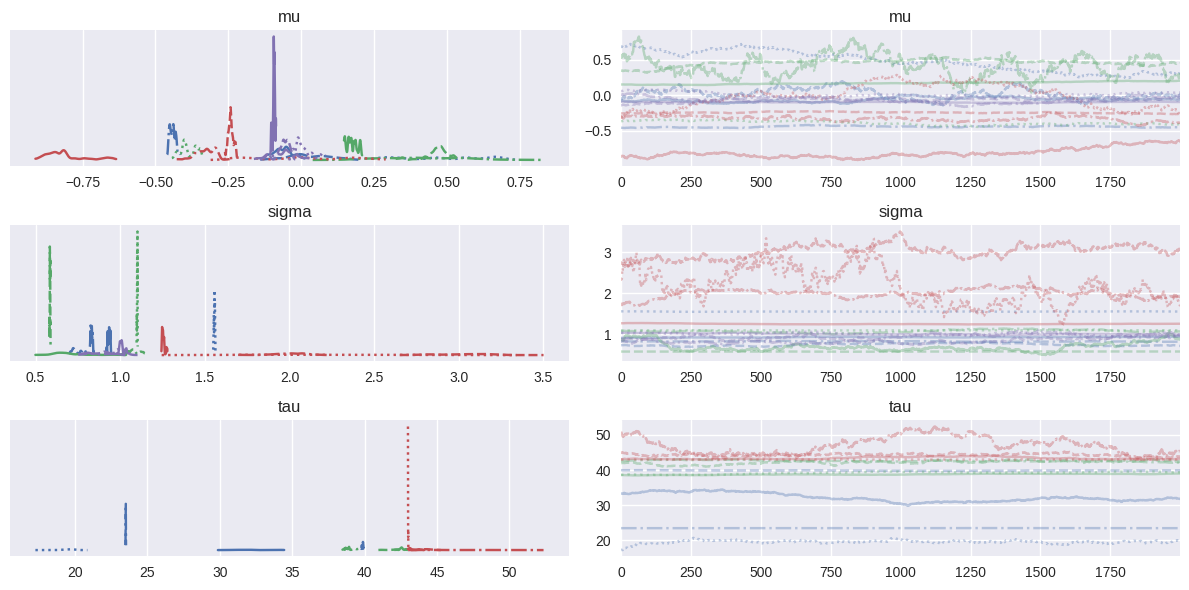

In [31]:
# Step 4: Model Diagnostics
summary = az.summary(trace, var_names=['mu', 'sigma', 'tau'])
print("Model Diagnostics (R-hat and ESS):")
print(summary)
az.plot_trace(trace, var_names=['mu', 'sigma', 'tau'])
plt.tight_layout()
plt.savefig(f'{base_path}/results/plots/trace_diagnostics.png')
plt.show()

In [32]:
# Step 5: Extract change points
tau_samples = trace.posterior['tau'].values  # Shape: (chains, draws, n_change_points)
change_points = np.clip(np.rint(np.mean(tau_samples, axis=(0, 1))).astype(int), 0, n_points - 1)
change_point_dates = dates[change_points]

# Calculate posterior probabilities using histogram bins
n_bins = min(50, n_points // 10)  # Adaptive bin size
probs = []
for i in range(n_change_points):
    hist, bin_edges = np.histogram(tau_samples[:, :, i].flatten(), bins=n_bins, range=(0, n_points), density=True)
    bin_idx = np.digitize(change_points[i], bin_edges) - 1
    bin_idx = np.clip(bin_idx, 0, len(hist) - 1)
    probs.append(hist[bin_idx] * (bin_edges[1] - bin_edges[0]))  # Probability density * bin width
change_point_probs = np.array(probs)

# Save results
results = pd.DataFrame({
    'Change_Point_Index': change_points,
    'Change_Point_Date': change_point_dates,
    'Posterior_Probability': change_point_probs
})
results_path = f'{base_path}/results/change_point_results.csv'
results.to_csv(results_path, index=False)
print("\nChange Point Results:")
print(results)


Change Point Results:
   Change_Point_Index Change_Point_Date  Posterior_Probability
0                  29        2001-12-31               0.275125
1                  41        2007-12-31               0.511000
2                  44        2009-06-30               0.988750


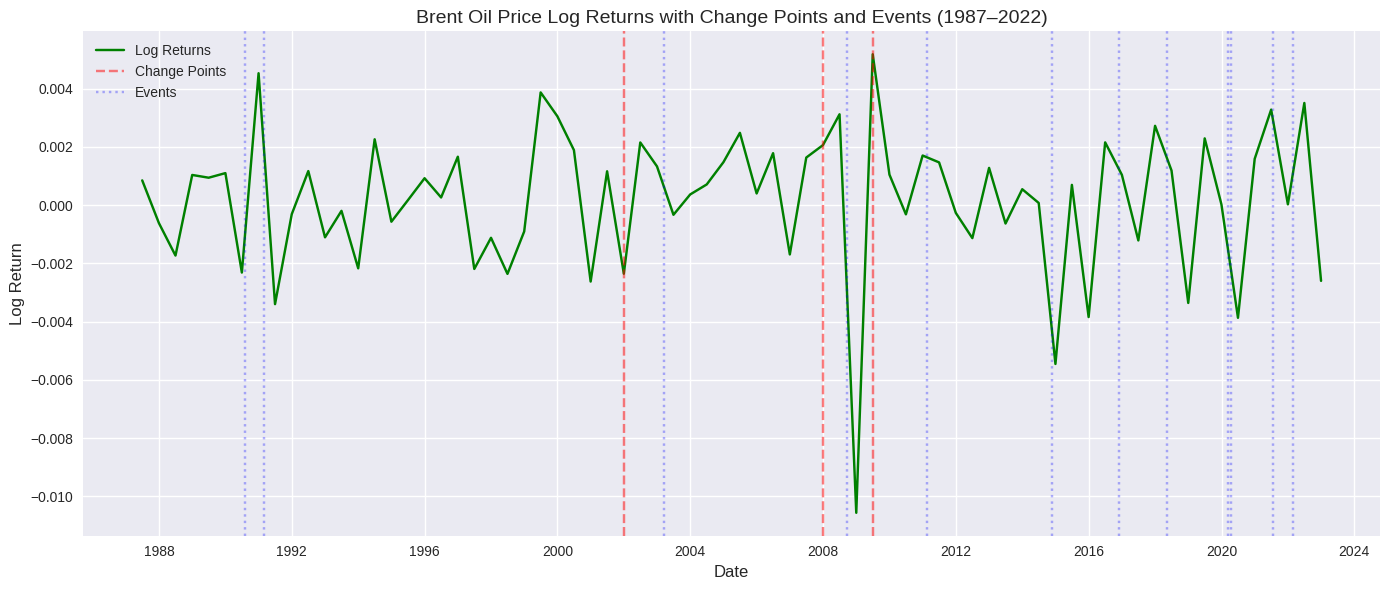

In [33]:
# Step 6: Visualize change points (Fixed)
plt.figure(figsize=(14, 6))
plt.plot(dates, log_returns, label='Log Returns', color='green')
for cp_date in change_point_dates:
    plt.axvline(cp_date, color='red', linestyle='--', alpha=0.5, label='Change Points' if cp_date == change_point_dates[0] else None)
for idx, row in events.iterrows():
    plt.axvline(row['Date'], color='blue', linestyle=':', alpha=0.3, label='Events' if idx == 0 else None)
plt.title('Brent Oil Price Log Returns with Change Points and Events (1987–2022)', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Log Return', fontsize=12)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(f'{base_path}/results/plots/change_points.png')
plt.show()

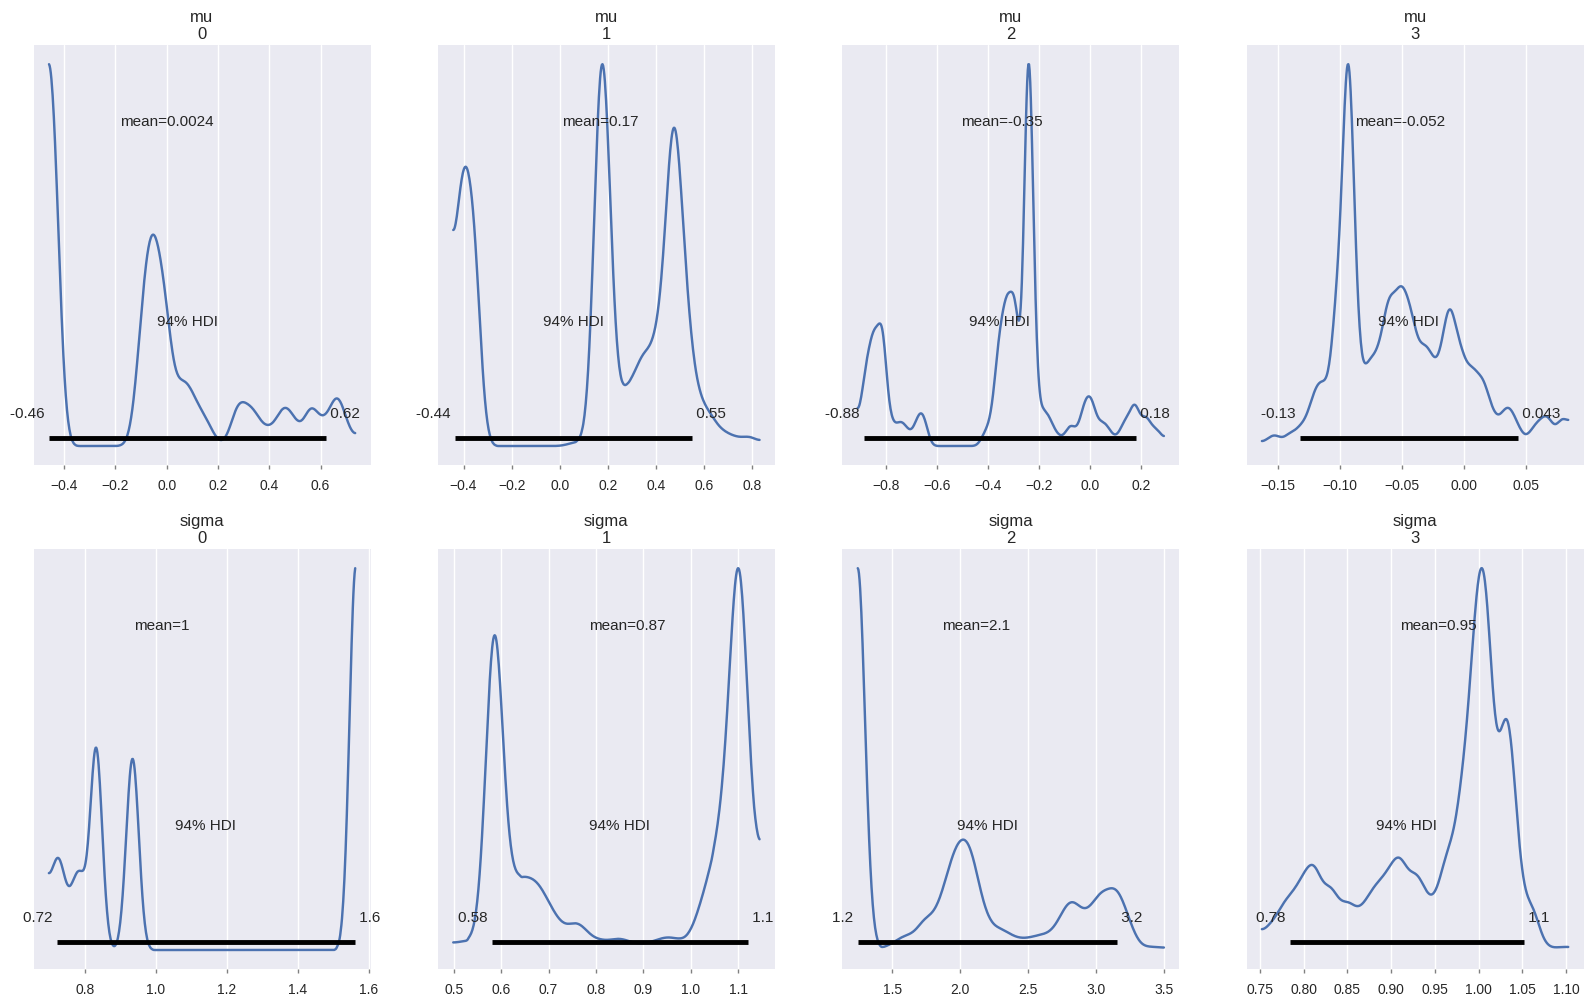

In [36]:
# Step 7: Posterior diagnostics
az.plot_posterior(trace, var_names=['mu', 'sigma'], figsize=(20, 12))
plt.savefig(f'{base_path}/results/plots/posterior_diagnostics.png')
plt.show()

In [35]:
# Step 8: Link Change Points to Events
print("\nChange Points and Nearest Events:")
for cp_date in change_point_dates:
    nearest_event = events.iloc[(events['Date'] - cp_date).abs().idxmin()]
    print(f"Change Point: {cp_date.date()} | Nearest Event: {nearest_event['Event']} ({nearest_event['Date'].date()})")


Change Points and Nearest Events:
Change Point: 2001-12-31 | Nearest Event: US-led invasion of Iraq (2003-03-20)
Change Point: 2007-12-31 | Nearest Event: Global Financial Crisis begins (2008-09-15)
Change Point: 2009-06-30 | Nearest Event: Global Financial Crisis begins (2008-09-15)
